(sec-13-1)=
# 13.1 Origins of the EEG, Montages and Rhythms

The EEG records small voltage differences at the scalp that reflect the combined activity of many neurons. Compared with an ECG, its rhythms are less tied to a repeating waveform, and the choice of reference can change how a channel looks. I start with those two ideas before moving to frequency bands.

We will connect the physiology to electrode placement, compare ways of forming channels, and inspect real recordings. The aim is to understand what a plotted EEG channel represents before interpreting a rhythm or applying a filter.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import mne
from scipy import signal

plt.style.use("../bsp.mplstyle")
C = plt.rcParams["axes.prop_cycle"].by_key()["color"]
rng = np.random.default_rng(42)
mne.set_log_level("ERROR")

(sec-13-1-1)=
## 13.1.1 Where the EEG Comes From

### Pyramidal neurons and postsynaptic currents

The cerebral cortex is a sheet of grey matter 2 to 4 mm thick, folded into gyri and sulci. Its most numerous excitatory cells, the **pyramidal neurons**, share a striking geometry: a long apical dendrite runs from the cell body up towards the cortical surface, and neighbouring pyramidal cells are aligned in parallel, like trees in a plantation. When an excitatory synapse on the apical dendrite opens, positive ions flow *into* the cell at that point. The current then flows along the inside of the dendrite and leaks out across the membrane farther away, near the soma. Seen from the extracellular space, the synapse is a current **sink** and the distant membrane is a **source**. A sink and a source separated by a few hundred micrometres form a **current dipole**, exactly the kind of source we met for the heart in [Section 1.2](../ch01_introduction/02_bioelectric_origins.ipynb).

The EEG is dominated by these **postsynaptic currents**, not by action potentials. The reason is timing. An action potential lasts about 1 ms, and the fields of thousands of asynchronous spikes rarely overlap. A postsynaptic potential lasts tens of milliseconds, so the currents of many synapses that are activated at slightly different times still add up. In addition, the sink–source pair of a postsynaptic current is spread along a long, straight dendrite, which produces a dipole whose field reaches far, whereas the field of a spike decays much faster with distance {cite:p}`buzsaki2012`.

### Synchrony: why only coordinated activity is visible

A single neuron's dipole is far too weak to be seen on the scalp. What we record is the sum of the dipoles of many millions of cells, and the size of that sum depends on how well they are synchronized. A short calculation makes the point. Suppose $N$ cortical patches each contribute an oscillation of amplitude $a$ at the same frequency $\omega$ but with phases $\varphi_k$. Using phasors ([Section 2.1](../ch02_math_toolkit/01_complex_numbers.ipynb)), the sum is

$$
\sum_{k=1}^{N} a\cos(\omega t + \varphi_k) = \operatorname{Re}\left\{a\,e^{j\omega t}\sum_{k=1}^{N} e^{j\varphi_k}\right\},
$$

On the left, we add $N$ oscillating sources, each with amplitude $a$ and its own phase $\varphi_k$. On the right, Euler's formula lets us collect their phases into a sum of arrows, then take the real part. Aligned arrows add directly; differently oriented arrows partly cancel. The calculation below asks how large that sum is on average when phases are independent and uniformly distributed.

so the amplitude of the total is $a\,\left|\sum_k e^{j\varphi_k}\right|$.

**Perfect synchrony.** If all phases are equal, every phasor points in the same direction and the amplitude is $Na$.

**No synchrony.** If the phases are independent and uniformly distributed on $[0, 2\pi)$, we compute the mean squared amplitude. Expanding the squared modulus as a double sum,

$$
\begin{aligned}
\mathbb{E}\left[\Big|\sum_{k=1}^{N} e^{j\varphi_k}\Big|^2\right]
&= \mathbb{E}\left[\sum_{k=1}^{N}\sum_{l=1}^{N} e^{j(\varphi_k - \varphi_l)}\right] \\
&= \sum_{k=1}^{N} 1 \;+\; \sum_{k \neq l} \mathbb{E}\left[e^{j\varphi_k}\right]\mathbb{E}\left[e^{-j\varphi_l}\right] \\
&= N + 0 = N.
\end{aligned}
$$

The diagonal terms ($k = l$) each equal one. The off-diagonal terms factor because the phases are independent, and each factor is the average of $e^{j\varphi}$ over a uniform phase, which is zero. The root-mean-square amplitude is therefore

(eq-13-1)=
\begin{equation*}
A_{\text{sync}} = N a, \qquad A_{\text{async}} = \sqrt{N}\,a, \qquad \frac{A_{\text{sync}}}{A_{\text{async}}} = \sqrt{N}. \tag{13.1}
\end{equation*}

With $N = 10^6$ contributing patches, synchronized activity is a thousand times larger than the same activity with random timing. Even a small synchronized fraction dominates: if only 1% of $10^6$ sources are in phase, they contribute $10^4 a$, against roughly $10^3 a$ from the other 99%. The EEG is therefore a measure of **synchrony** as much as of activity. A cortex that is very busy but desynchronized can produce a *smaller* EEG than a cortex that is idling in a coordinated rhythm, and we will see exactly this when the alpha rhythm disappears on eye opening.

We can check equation [(13.1)](#eq-13-1) by simulation.

In [2]:
def rms_sum_amplitude(n_sources, frac_sync, n_rep=200):
    """RMS amplitude of a sum of unit phasors when a fraction of them share one phase."""
    n_sync = int(round(frac_sync * n_sources))
    power = np.empty(n_rep)
    for r in range(n_rep):
        phases = rng.uniform(0, 2 * np.pi, n_sources - n_sync)
        power[r] = np.abs(n_sync + np.exp(1j * phases).sum()) ** 2
    return np.sqrt(power.mean())


n_values = np.unique(np.logspace(0, 5, 16).astype(int))
amp_async = np.array([rms_sum_amplitude(n, 0.0) for n in n_values])
amp_partial = np.array([rms_sum_amplitude(n, 0.05) for n in n_values])

for n in (100, 10_000):
    a_r = rms_sum_amplitude(n, 0.0, n_rep=400)
    print(f"N = {n:>6d}: synchronized {n:8.0f}   random phases {a_r:7.1f}   sqrt(N) = {np.sqrt(n):6.1f}")

N =    100: synchronized      100   random phases     9.9   sqrt(N) =   10.0
N =  10000: synchronized    10000   random phases   100.2   sqrt(N) =  100.0


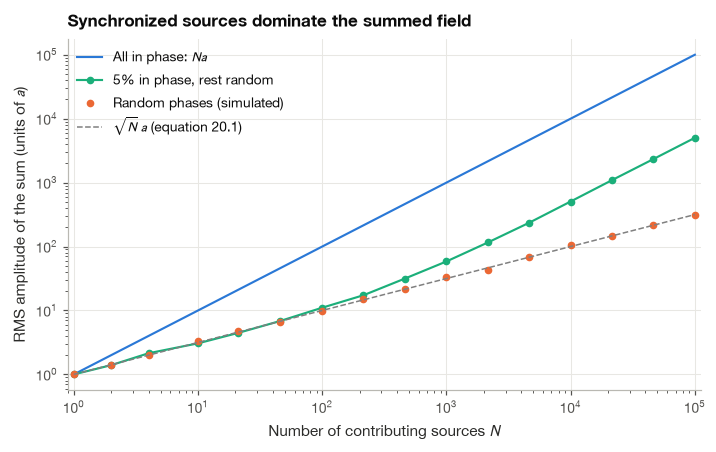

In [3]:
fig, ax = plt.subplots(figsize=(6.4, 4.0))
ax.loglog(n_values, n_values, color=C[0], label="All in phase: $N a$")
ax.loglog(n_values, amp_partial, "o-", color=C[2], ms=4, label="5% in phase, rest random")
ax.loglog(n_values, amp_async, "o", color=C[1], ms=4, label=r"Random phases (simulated)")
ax.loglog(n_values, np.sqrt(n_values), "--", color="0.5", lw=1, label=r"$\sqrt{N}\,a$ (equation 20.1)")
ax.set(xlabel="Number of contributing sources $N$", ylabel="RMS amplitude of the sum (units of $a$)",
       title="Synchronized sources dominate the summed field")
ax.legend(loc="upper left")
plt.show()

The simulated amplitudes for random phases sit on the $\sqrt{N}$ line, and the curve with only 5% synchronized sources quickly bends away from it and runs parallel to the fully synchronized line, at one twentieth of its height.

### Dipole layers and volume conduction

Because neighbouring pyramidal cells are parallel, a patch of synchronously active cortex behaves like a **dipole layer**: a sheet of aligned dipoles whose axis is perpendicular to the local cortical surface. On the crown of a gyrus the sheet faces the scalp and produces a **radial** dipole. In the wall of a sulcus it is turned sideways and produces a **tangential** dipole. Activity on the two opposite walls of a sulcus, or in a deep fold, partly cancels.

Between the dipole layer and the electrode lie cerebrospinal fluid, the skull and the scalp. They form a **volume conductor**, and the electrode measures the potential that the source currents create as they spread through it. In an infinite homogeneous medium of conductivity $\sigma$, a current dipole of moment $p$ produces at distance $r$ and angle $\theta$ from its axis the potential

$$
V(r, \theta) = \frac{p\cos\theta}{4\pi\sigma r^2},
$$

so the field decays with the square of the distance. The head is not homogeneous, and the skull matters most: it conducts electricity much less well than brain or scalp (published estimates of the conductivity ratio range from about 1:15 to 1:80). Current reaching the skull spreads sideways in the scalp before it can be picked up, which acts as a **spatial low-pass filter**. A focal source is smeared over several centimetres of scalp, and every electrode sees a weighted sum of many sources.

Put these facts together and the microvolt scale follows. Inside the cortex the local field potential reaches hundreds of microvolts to about a millivolt. On the cortical surface it is still of that order. After distance, cancellation between differently oriented patches and the skull's smoothing, the scalp EEG of an awake adult is typically 10 to 100 µV {cite:p}`buzsaki2012`. A scalp-detectable discharge usually needs synchronous activity over several square centimetres of cortex, which is why small or deep sources can be invisible at the scalp even when they are clinically important.

(sec-13-1-2)=
## 13.1.2 EEG, MEG, ECoG and LFP

The same postsynaptic currents can be recorded at different distances from the brain, and the choice is a trade-off between invasiveness and signal quality. Magnetoencephalography (MEG) measures the tiny magnetic field produced by the same currents with superconducting or optically pumped sensors outside the head. Because the skull is transparent to magnetic fields, MEG blurs less than EEG, but it is mostly blind to radial dipoles and needs a magnetically shielded room. Electrocorticography (ECoG) places electrode grids directly on the cortex during neurosurgery, typically to localize seizure onset before epilepsy surgery. Local field potentials (LFP) are recorded with microelectrodes inside the brain tissue, mostly in animal research and during deep brain stimulation procedures in humans.

The table below gives order-of-magnitude values. They vary with electrode size, the region studied and the definition of "resolution", so treat them as a map of the trade-offs rather than as specifications.

| | Scalp EEG | MEG | ECoG | LFP |
|---|---|---|---|---|
| Sensor position | On the scalp | 2–3 cm above the scalp (helmet) | On the cortical surface | Inside the cortex |
| Invasiveness | None | None | Craniotomy | Penetrating microelectrodes |
| Typical amplitude | 10–100 µV | 50–500 fT | 50 µV – 1 mV | up to about 1 mV |
| Spatial resolution | Several cm | About 0.5–1 cm (after source modelling) | About 1 cm to a few mm | Below 1 mm |
| Temporal resolution | Milliseconds | Milliseconds | Milliseconds | Below 1 ms |
| Useful bandwidth | About 0.5–70 Hz (gamma weak, muscle-contaminated) | Similar to EEG, less muscle | Up to 200 Hz and more (high gamma) | Up to a few hundred Hz |
| Signal-to-noise ratio | Lowest | Low to moderate | High | Highest |
| Typical use | Clinic, sleep, ICU, BCI | Research, presurgical mapping | Epilepsy surgery planning, research BCIs | Animal research, DBS |

All four methods share millisecond time resolution, because volume conduction is effectively instantaneous at these frequencies. What separates them is spatial detail and noise. The rest of this chapter is about scalp EEG, the only one of the four that is routinely available outside a hospital or a laboratory.

(sec-13-1-3)=
## 13.1.3 The 10–20 System and Its 10-10 Extension

To compare recordings across patients and laboratories, electrode positions must be defined by anatomy, not by eye. The **International 10–20 system** {cite:p}`jasper1958` does this with four landmarks: the **nasion** (the dip between the forehead and the nose), the **inion** (the bony bump at the back of the skull) and the two **preauricular points** in front of the ears. The midline arc from nasion to inion is measured and divided into steps of 10% and 20% of its length: Fpz sits 10% above the nasion, then Fz, Cz and Pz follow at 20% intervals, and Oz lies 10% above the inion. The same proportional rule applied to the arc between the preauricular points places T7, C3, Cz, C4 and T8. Because the positions are proportions of each person's own head, an electrode labelled C3 lies over roughly the same part of the cortex in a small child and in a large adult.

The labels follow a simple code:

- **Letters** give the region: Fp (frontopolar), F (frontal), C (central), P (parietal), O (occipital) and T (temporal). There is no central lobe; "C" denotes the region around the central sulcus, over the primary motor and somatosensory cortex.
- **Odd numbers** are on the left hemisphere and **even numbers** on the right; the numbers grow with distance from the midline.
- **z** (zero) marks the midline: Fz, Cz, Pz, Oz.

The original system has 19 recording sites plus the ear (or mastoid) references. For denser coverage, the **10-10 system** fills in intermediate positions at 10% spacing and introduces combined letters such as AF (between Fp and F), FC, CP, PO, FT and TP. It also renamed four temporal sites: the old T3, T4, T5 and T6 became T7, T8, P7 and P8. The eegmmidb recordings use 64 positions from this extended system, and MNE's `standard_1005` montage supplies their template 3-D coordinates from a still denser five-percent scheme {cite:p}`oostenveld2001`.

In [4]:
def load_run(run):
    """Read one eegmmidb run of subject S001 with standard names and 10-05 positions."""
    raw = mne.io.read_raw_edf(f"../data/eegmmidb/S001{run}.edf", preload=True)
    mne.datasets.eegbci.standardize(raw)
    raw.set_montage("standard_1005")
    raw.crop(tmax=60.0, include_tmax=False)  # the files end with ~1 s of zero padding
    return raw


raw_open = load_run("R01")
raw_closed = load_run("R02")
fs = raw_closed.info["sfreq"]
ch_names = raw_closed.ch_names

ten_twenty = ["Fp1", "Fpz", "Fp2", "F7", "F3", "Fz", "F4", "F8", "T7", "C3", "Cz", "C4", "T8",
              "P7", "P3", "Pz", "P4", "P8", "O1", "Oz", "O2"]
print(f"Channels: {len(ch_names)}, sampling rate: {fs:.0f} Hz, duration: {raw_closed.times[-1] + 1 / fs:.1f} s")
print(f"10-20 positions present: {sum(c in ch_names for c in ten_twenty)} of {len(ten_twenty)}")
print(f"Additional 10-10 positions: {len(ch_names) - len(ten_twenty)}")

Channels: 64, sampling rate: 160 Hz, duration: 60.0 s
10-20 positions present: 21 of 21
Additional 10-10 positions: 43


To draw the layout we need a flat map of electrodes that really sit on a curved head. We fit a sphere to the 64 template positions by linear least squares (the condition $\lVert\mathbf{p}_i - \mathbf{c}\rVert^2 = R^2$ rearranges to $2\mathbf{p}_i^{\top}\mathbf{c} + (R^2 - \lVert\mathbf{c}\rVert^2) = \lVert\mathbf{p}_i\rVert^2$, which is linear in the unknowns), then use an azimuthal equidistant projection: each electrode is plotted at a distance from the centre equal to its angle from the vertex, in the direction of its azimuth. This is the same idea MNE uses for its topographic maps.

In [5]:
def project_to_2d(info):
    """Fit a sphere to the electrode positions; return 2-D azimuthal equidistant coordinates and the radius."""
    pos = np.array([info["chs"][i]["loc"][:3] for i in range(info["nchan"])])
    A = np.column_stack([2 * pos, np.ones(len(pos))])
    sol, *_ = np.linalg.lstsq(A, (pos ** 2).sum(axis=1), rcond=None)
    v = pos - sol[:3]
    polar = np.arccos(v[:, 2] / np.linalg.norm(v, axis=1))   # angle from the vertex (rad)
    azimuth = np.arctan2(v[:, 1], v[:, 0])                   # +y points to the nose
    radius = np.sqrt(sol[3] + sol[:3] @ sol[:3])
    return np.column_stack([polar * np.cos(azimuth), polar * np.sin(azimuth)]), radius


xy, head_radius = project_to_2d(raw_closed.info)
ring = np.mean([np.hypot(*xy[ch_names.index(c)]) for c in ("Fpz", "T7", "Oz", "T8")])
print(f"Radius of the fitted sphere: {100 * head_radius:.1f} cm")
for name in ("Cz", "C3", "O1"):
    px, py = xy[ch_names.index(name)]
    print(f"  {name:<3s} projected to x = {px:+.3f}, y = {py:+.3f} (radians from the vertex)")

Radius of the fitted sphere: 9.6 cm
  Cz  projected to x = -0.005, y = +0.130 (radians from the vertex)
  C3  projected to x = -0.826, y = +0.104 (radians from the vertex)
  O1  projected to x = -0.447, y = -1.391 (radians from the vertex)


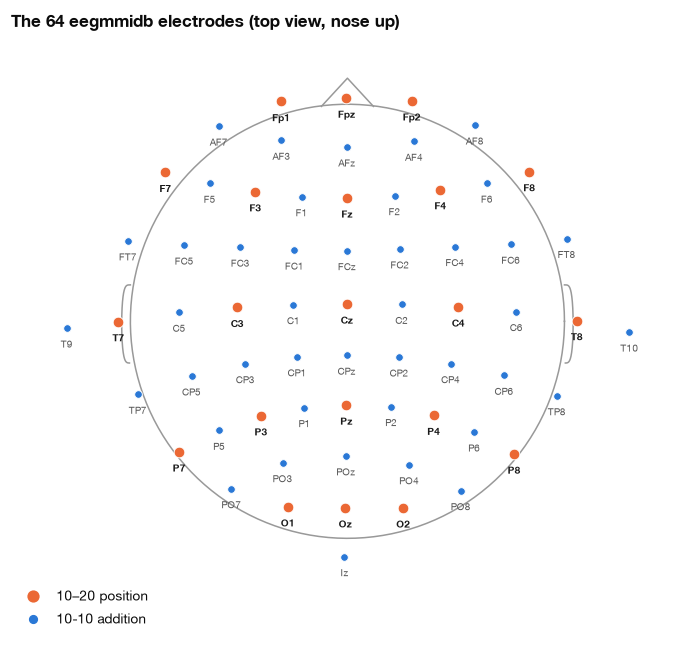

In [6]:
fig, ax = plt.subplots(figsize=(6.2, 6.2))
theta = np.linspace(0, 2 * np.pi, 300)
ax.plot(ring * np.cos(theta), ring * np.sin(theta), color="0.6", lw=1)
ax.plot([-0.12 * ring, 0, 0.12 * ring], [0.99 * ring, 1.12 * ring, 0.99 * ring], color="0.6", lw=1)
for side in (-1, 1):
    ax.plot(side * ring * (1 + 0.04 * np.sin(theta[:150]) ** 0.5), 0.18 * ring * np.cos(theta[:150]) - 0.02,
            color="0.6", lw=1)
for name, (x, y) in zip(ch_names, xy):
    is_1020 = name in ten_twenty
    ax.plot(x, y, "o", ms=7 if is_1020 else 5, color=C[1] if is_1020 else C[0],
            mec="white", mew=0.6, zorder=3)
    ax.text(x, y - 0.075, name, ha="center", va="top", fontsize=6.5,
            fontweight="bold" if is_1020 else "normal", color="0.1" if is_1020 else "0.35")
ax.plot([], [], "o", color=C[1], ms=7, label="10–20 position")
ax.plot([], [], "o", color=C[0], ms=5, label="10-10 addition")
ax.set(xlim=(-1.55 * ring, 1.55 * ring), ylim=(-1.45 * ring, 1.3 * ring),
       title="The 64 eegmmidb electrodes (top view, nose up)")
ax.set_aspect("equal")
ax.axis("off")
ax.legend(loc="lower left", bbox_to_anchor=(0.0, 0.0))
plt.show()

The orange electrodes form the classic 10–20 grid; the blue ones are the 10-10 additions. The head outline is drawn through Fpz, T7, Oz and T8, the 10% ring; T9, T10 and Iz lie below it and therefore appear outside. Left is on the left of the figure (odd numbers), as if we were looking down on the head from above.

(sec-13-1-4)=
## 13.1.4 References and Montages

### Every EEG channel is a difference

An amplifier cannot measure the potential at a single point; it measures a voltage between two points. If $\phi_i(t)$ is the potential at electrode $i$ relative to some ideal "zero" that we can never access, the recorded **referential** signal is

$$
v_i(t) = \phi_i(t) - \phi_{\text{ref}}(t),
$$

where $\phi_{\text{ref}}$ is the potential at the reference electrode (an earlobe, the mastoids, the vertex or the nose, depending on the system). There is no electrically silent place on the body, so $\phi_{\text{ref}}$ is never truly zero, and every activity under the reference electrode appears in *every* channel with the same waveform. A **montage** is the rule we use to combine the recorded channels into the derivations we display. Clinical EEG readers switch between montages constantly, because each one highlights different features. Here are the four I consider essential, each derived from the referential signals.

### Common average reference

The **common average reference** (CAR) subtracts the instantaneous mean of all $M$ channels from each one:

(eq-13-2)=
\begin{equation*}
\begin{aligned}
v_i^{\text{CAR}} &= v_i - \frac{1}{M}\sum_{k=1}^{M} v_k \\
&= \big(\phi_i - \phi_{\text{ref}}\big) - \frac{1}{M}\sum_{k=1}^{M}\big(\phi_k - \phi_{\text{ref}}\big) \\
&= \phi_i - \phi_{\text{ref}} - \bar{\phi} + \phi_{\text{ref}} \\
&= \phi_i - \bar{\phi}, \qquad \bar{\phi} = \frac{1}{M}\sum_{k=1}^{M}\phi_k .
\end{aligned} \tag{13.2}
\end{equation*}

In the third line we used the fact that $\phi_{\text{ref}}$ appears $M$ times in the sum and so survives the averaging unchanged; it then cancels. The CAR signal is therefore **independent of the original reference**: it is the potential relative to the average of all electrodes. If the electrodes covered the whole head uniformly, that average would be close to zero, because the potential of a dipole inside a sphere integrates to zero over the sphere's surface. Real caps do not cover the lower half of the head, so the average is only an approximation of a neutral reference.

In matrix form, with $\mathbf{v}(t)$ the vector of $M$ channels and $\mathbf{1}$ a vector of ones, $\mathbf{v}^{\text{CAR}} = \left(\mathbf{I} - \tfrac{1}{M}\mathbf{1}\mathbf{1}^{\top}\right)\mathbf{v}$. The matrix in brackets is a projection: applying it twice changes nothing, and it removes exactly one direction (the common mode $\mathbf{1}$). Two practical consequences follow. First, the CAR channels always sum to zero, so their rank is $M - 1$; algorithms such as ICA (Chapter 25) must account for that lost dimension. Second, the average itself contains every strong local event, so a large artifact at a few electrodes is subtracted, with a sign flip, from every other channel.

### Bipolar montages

A **bipolar** derivation is the difference of two neighbouring electrodes,

(eq-13-3)=
\begin{equation*}
v_{i,j}^{\text{bip}} = v_i - v_j = (\phi_i - \phi_{\text{ref}}) - (\phi_j - \phi_{\text{ref}}) = \phi_i - \phi_j, \tag{13.3}
\end{equation*}

and again the reference cancels. Clinical bipolar montages chain neighbouring electrodes together, for example front to back along each side of the head (Fp1–F7, F7–T7, T7–P7, P7–O1 on the left), which gives the "double banana" layout. A bipolar channel is sensitive to the local *gradient* of the potential and largely blind to activity that is common to both electrodes.

**Example 13.1.1 (phase reversal).** Five electrodes along a chain sit above a focal negative discharge centred under electrode 3. At the peak of the discharge the referential potentials are $(-5, -20, -60, -20, -5)$ µV plus an unknown reference contribution $r$. Find the bipolar chain and the common average over these five electrodes.

The bipolar channels are differences of consecutive electrodes, so $r$ disappears:

$$
(v_1 - v_2,\; v_2 - v_3,\; v_3 - v_4,\; v_4 - v_5) = (15,\; 40,\; -40,\; -15)\ \text{µV}.
$$

The two channels that share electrode 3 deflect in *opposite* directions. This **phase reversal** is how electroencephalographers localize a focal discharge on a bipolar display: the reversal points to the electrode nearest the source. For the common average, the mean of the five values is $-22$ µV (plus $r$, which cancels again), so

$$
v^{\text{CAR}} = (17,\; 2,\; -38,\; 2,\; 17)\ \text{µV}.
$$

The peak is still at electrode 3, but the two outer electrodes now show a *positive* deflection that does not exist in the true potentials. It is an artifact of subtracting an average that is dominated by the discharge itself, and it becomes worse when few electrodes are averaged.

In [7]:
r = 37.0                                         # arbitrary reference contribution (uV)
v_ref = np.array([-5, -20, -60, -20, -5]) + r
bipolar = v_ref[:-1] - v_ref[1:]
car = v_ref - v_ref.mean()
print("Bipolar chain (uV):", bipolar)
print("Common average (uV):", car)

Bipolar chain (uV): [ 15.  40. -40. -15.]
Common average (uV): [ 17.   2. -38.   2.  17.]


### The surface Laplacian

Both CAR and bipolar derivations remove the reference, but neither isolates local activity very well. The **surface Laplacian** does better. On a flat patch of scalp with coordinates $(x, y)$, the Laplacian of the potential is $\nabla^2\phi = \partial^2\phi/\partial x^2 + \partial^2\phi/\partial y^2$. Physically, the Laplacian of the scalp potential is proportional to the current density flowing radially through the skull at that point, which is why it is also called the **current source density**. It responds to sources directly beneath the electrode and suppresses broad fields from distant or deep sources.

To compute it from discrete electrodes, take an electrode at $(x, y)$ with four neighbours at distance $d$ to the left, right, front and back. A Taylor expansion along $x$ gives

$$
\begin{aligned}
\phi(x + d, y) &= \phi + d\,\phi_x + \tfrac{d^2}{2}\phi_{xx} + \tfrac{d^3}{6}\phi_{xxx} + O(d^4), \\
\phi(x - d, y) &= \phi - d\,\phi_x + \tfrac{d^2}{2}\phi_{xx} - \tfrac{d^3}{6}\phi_{xxx} + O(d^4).
\end{aligned}
$$

Adding the two lines cancels the odd-order terms: $\phi(x+d, y) + \phi(x-d, y) = 2\phi + d^2\phi_{xx} + O(d^4)$. The same holds along $y$. Adding all four neighbours and rearranging,

$$
\nabla^2\phi \approx \frac{1}{d^2}\left(\sum_{k=1}^{4}\phi_k - 4\phi\right) = -\frac{4}{d^2}\left(\phi - \frac{1}{4}\sum_{k=1}^{4}\phi_k\right).
$$

The bracket is the **nearest-neighbour (Hjorth) Laplacian** {cite:p}`hjorth1975`:

(eq-13-4)=
\begin{equation*}
L_i = v_i - \frac{1}{4}\sum_{k \in \mathcal{N}(i)} v_k . \tag{13.4}
\end{equation*}

The reference cancels once more, because the four weights $\tfrac14$ sum to one. Up to the factor $-4/d^2$, $L_i$ estimates the surface Laplacian. For C3, the neighbours in the 10-10 grid are FC3, C5, C1 and CP3. Spherical-spline methods give smoother estimates at the cost of more computation, but equation [(13.4)](#eq-13-4) already shows the essential behaviour.

### Montage matters: one electrode, four answers

Here is the alpha content at C3 during eyes-closed rest, computed in the four montages. The occipital alpha rhythm is strong in this recording, and volume conduction carries part of it to central electrodes.

In [8]:
sos_display = signal.butter(2, [0.5, 40], btype="bandpass", fs=fs, output="sos")
x_closed = signal.sosfiltfilt(sos_display, raw_closed.get_data() * 1e6, axis=1)   # uV
idx = {name: k for k, name in enumerate(ch_names)}

derivations = {
    "Referential C3": x_closed[idx["C3"]],
    "Common average C3": x_closed[idx["C3"]] - x_closed.mean(axis=0),
    "Bipolar C3-P3": x_closed[idx["C3"]] - x_closed[idx["P3"]],
    "Laplacian C3": x_closed[idx["C3"]] - x_closed[[idx[c] for c in ("FC3", "C5", "C1", "CP3")]].mean(axis=0),
}

rows = []
for name, v in derivations.items():
    f, psd = signal.welch(v, fs, nperseg=int(4 * fs))
    df = f[1] - f[0]
    total = psd[(f >= 1) & (f <= 40)].sum() * df
    alpha = psd[(f >= 8) & (f <= 13)].sum() * df
    rows.append({"Derivation": name, "Power 1-40 Hz (uV^2)": round(total, 1),
                 "Alpha 8-13 Hz (uV^2)": round(alpha, 1), "Alpha fraction": round(alpha / total, 2)})
pd.DataFrame(rows).set_index("Derivation")

,Power 1-40 Hz (uV^2),Alpha 8-13 Hz (uV^2),Alpha fraction
Derivation,,,
Referential C3,1662.5,606.1,0.36
Common average C3,308.4,151.7,0.49
Bipolar C3-P3,805.0,490.2,0.61
Laplacian C3,20.5,4.5,0.22


The same electrode gives four quite different pictures. The referential signal carries a large common component (its power is more than five times that of the CAR signal). The bipolar C3–P3 channel has the highest alpha fraction, but much of that alpha comes from P3, which is closer to the occipital generators. The Laplacian is the smallest signal by far, because neighbouring electrodes only 3 to 4 cm apart share most of their activity, and its alpha fraction is the lowest: much of the alpha seen at C3 in the other montages is far-field activity from posterior cortex, not local sensorimotor (mu) rhythm. None of these numbers is "the" alpha power at C3. Each answers a slightly different question, and I recommend stating the montage alongside every EEG result.

### A real artifact under the common average

The common average can also move artifacts around. Eye blinks produce a large positive deflection at the frontopolar electrodes (we look at them closely in [Section 13.1.6](#sec-13-1-6)). The next figure shows one blink from the eyes-open run in the referential and the CAR montages.

In [9]:
x_open = signal.sosfiltfilt(sos_display, raw_open.get_data() * 1e6, axis=1)
x_open_car = x_open - x_open.mean(axis=0)
t_open = np.arange(x_open.shape[1]) / fs

blink_t = 9.67                                       # a blink found in Section 20.1.6
win = (t_open > blink_t - 0.8) & (t_open < blink_t + 1.2)
peak = np.argmin(np.abs(t_open - blink_t))
for name in ("Fp1", "Cz", "O1"):
    k = idx[name]
    seg = slice(peak - 8, peak + 8)
    print(f"{name:>3s}: referential peak {x_open[k, seg].max():6.1f} uV   "
          f"CAR extreme {x_open_car[k, seg][np.argmax(np.abs(x_open_car[k, seg]))]:6.1f} uV")
print(f"Mean of all 64 channels at the blink peak: {x_open[:, peak].mean():.1f} uV")

Fp1: referential peak  593.1 uV   CAR extreme  450.1 uV
 Cz: referential peak  100.8 uV   CAR extreme  -63.8 uV
 O1: referential peak   37.3 uV   CAR extreme -117.7 uV
Mean of all 64 channels at the blink peak: 143.8 uV


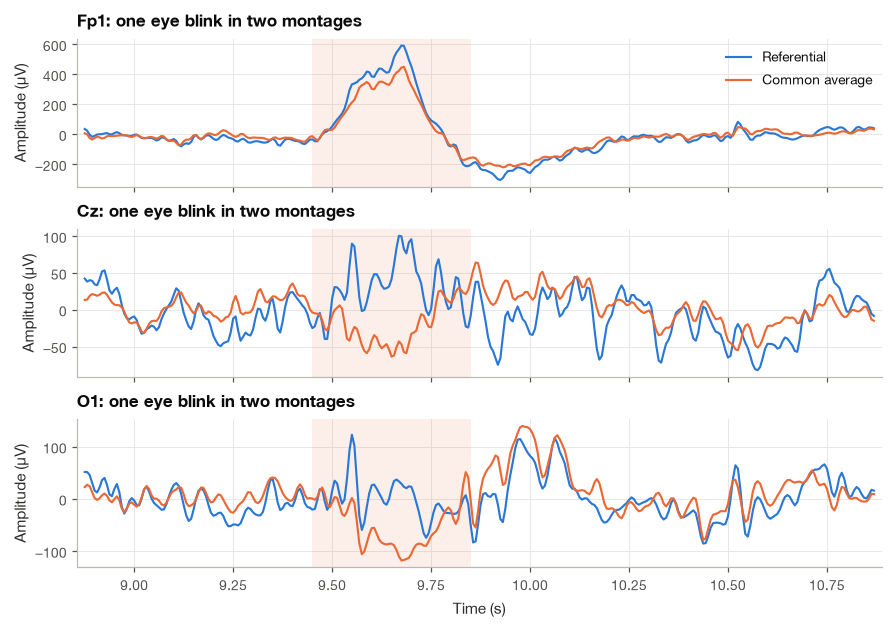

In [10]:
fig, axes = plt.subplots(3, 1, figsize=(8, 5.6), sharex=True)
for ax, name in zip(axes, ("Fp1", "Cz", "O1")):
    k = idx[name]
    ax.axvspan(9.45, 9.85, color=C[1], alpha=0.1, lw=0)
    ax.plot(t_open[win], x_open[k, win], color=C[0], label="Referential")
    ax.plot(t_open[win], x_open_car[k, win], color=C[1], label="Common average")
    ax.set(ylabel="Amplitude (µV)", title=f"{name}: one eye blink in two montages")
axes[0].legend(loc="upper right")
axes[-1].set_xlabel("Time (s)")
plt.show()

In the referential montage the blink is large at Fp1, smaller at Cz and barely visible at O1. After CAR it appears at O1 as an *inverted* blink of about $-120$ µV, larger than the occipital EEG itself. Nothing happened at O1; the blink entered the average (about 145 µV at its peak, because the blink field is large over the many frontal electrodes) and was subtracted from every channel. For this reason I remove or reject large artifacts before re-referencing to the average, never after.

(sec-13-1-5)=
## 13.1.5 The EEG Rhythms

Scalp EEG is broadband, but its spectrum is traditionally divided into bands that correspond, loosely, to brain states. The boundaries are conventions and differ by a hertz or so between laboratories; the table gives common choices.

| Band | Range (Hz) | Where and when it is typically seen |
|---|---|---|
| Delta ($\delta$) | 0.5–4 | Deep (N3) sleep; normal in infants. Focal delta in an awake adult suggests a structural lesion. |
| Theta ($\theta$) | 4–8 | Drowsiness and light sleep; prominent in children. Frontal midline theta during sustained mental effort. |
| Alpha ($\alpha$) | 8–13 | Relaxed wakefulness with eyes closed, maximal over occipital and parietal regions; attenuated by eye opening and visual attention. |
| Mu ($\mu$) | 8–13 | Over sensorimotor cortex at rest; attenuated by movement, touch and motor imagery (Section 13.3). |
| Beta ($\beta$) | 13–30 | Alert wakefulness, frontal and central; increased by benzodiazepines and barbiturates. |
| Gamma ($\gamma$) | above 30 | Local cortical processing; small at the scalp and easily confused with muscle activity. |

The next figure shows six seconds of the eyes-closed recording at ten classic 10–20 electrodes, ordered from front to back. The alpha rhythm is the regular 10 Hz oscillation that dominates O1 and O2 and fades towards the front of the head.

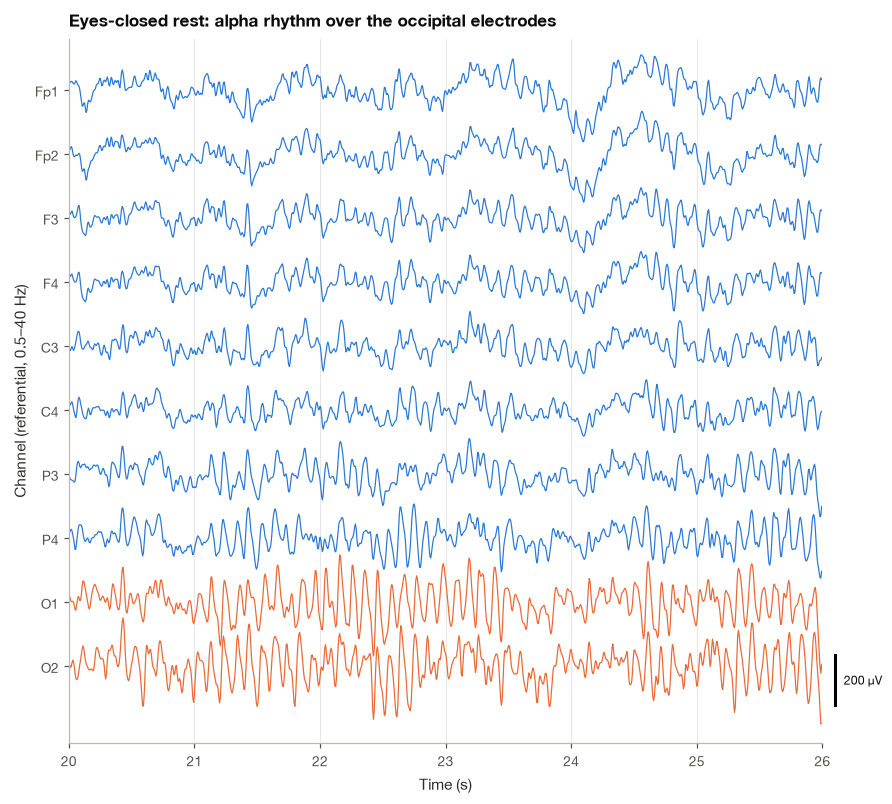

In [11]:
stack = ["Fp1", "Fp2", "F3", "F4", "C3", "C4", "P3", "P4", "O1", "O2"]
t_closed = np.arange(x_closed.shape[1]) / fs
seg = (t_closed >= 20) & (t_closed < 26)
offset = 260.0

fig, ax = plt.subplots(figsize=(8, 7.2))
for row, name in enumerate(stack):
    color = C[1] if name in ("O1", "O2") else C[0]
    ax.plot(t_closed[seg], x_closed[idx[name], seg] - row * offset, color=color, lw=0.8)
ax.set_yticks(-offset * np.arange(len(stack)), stack)
ax.plot([26.1, 26.1], [-9.6 * offset, -9.6 * offset + 200], color="k", lw=2, clip_on=False)
ax.text(26.17, -9.6 * offset + 100, "200 µV", va="center", fontsize=8)
ax.set(xlabel="Time (s)", ylabel="Channel (referential, 0.5–40 Hz)", xlim=(20, 26),
       ylim=(-10.2 * offset, 0.8 * offset),
       title="Eyes-closed rest: alpha rhythm over the occipital electrodes")
ax.grid(axis="y", visible=False)
plt.show()

To see the bands separately, we split one channel, O1, into the five classic bands with zero-phase Butterworth band-pass filters (zero-phase so that the band components stay aligned with the original in time; see Section 15.3). The RMS value of each band component is a first measure of how much of the signal lives in that band; Section 13.2 refines this into proper band powers.

In [12]:
bands = {"Delta": (0.5, 4), "Theta": (4, 8), "Alpha": (8, 13), "Beta": (13, 30), "Gamma": (30, 45)}
o1 = x_closed[idx["O1"]]

band_signals = {}
for name, (lo, hi) in bands.items():
    sos = signal.butter(4, [lo, hi], btype="bandpass", fs=fs, output="sos")
    band_signals[name] = signal.sosfiltfilt(sos, o1)

print(f"O1, eyes closed, RMS of the 0.5-40 Hz signal: {np.sqrt(np.mean(o1 ** 2)):5.1f} uV")
for name, xb in band_signals.items():
    print(f"  {name:<6s} {bands[name][0]:>4} - {bands[name][1]:<3} Hz : RMS {np.sqrt(np.mean(xb ** 2)):5.1f} uV")

O1, eyes closed, RMS of the 0.5-40 Hz signal:  74.7 uV
  Delta   0.5 - 4   Hz : RMS  29.6 uV
  Theta     4 - 8   Hz : RMS  16.7 uV
  Alpha     8 - 13  Hz : RMS  60.1 uV
  Beta     13 - 30  Hz : RMS  24.5 uV
  Gamma    30 - 45  Hz : RMS   3.6 uV


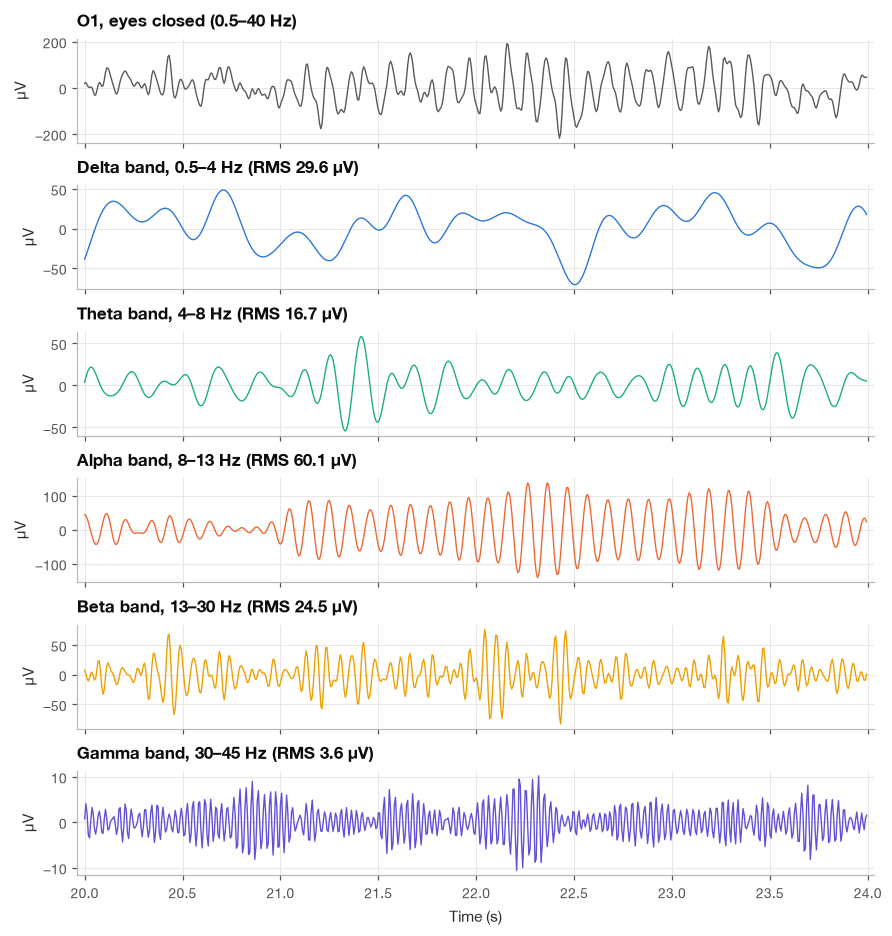

In [13]:
seg = (t_closed >= 20) & (t_closed < 24)
fig, axes = plt.subplots(6, 1, figsize=(8, 8.4), sharex=True)
axes[0].plot(t_closed[seg], o1[seg], color="0.35", lw=0.9)
axes[0].set(ylabel="µV", title="O1, eyes closed (0.5–40 Hz)")
for ax, (name, xb), color in zip(axes[1:], band_signals.items(), [C[0], C[2], C[1], C[3], C[6]]):
    ax.plot(t_closed[seg], xb[seg], color=color, lw=0.9)
    lo, hi = bands[name]
    ax.set(ylabel="µV", title=f"{name} band, {lo}–{hi} Hz (RMS {np.sqrt(np.mean(xb ** 2)):.1f} µV)")
axes[-1].set_xlabel("Time (s)")
plt.show()

The alpha component carries by far the most energy and waxes and wanes in "spindles" lasting a second or two, a nonstationary behaviour that we quantify with the Hilbert transform in Section 23.4. The delta component is substantial too, but much of it in a resting awake adult comes from slow drifts and eye movements rather than from cortex. The gamma component is tiny, a few microvolts, which is why scalp gamma measurements are so vulnerable to the much larger electrical activity of the scalp and jaw muscles.

(sec-13-1-6)=
## 13.1.6 Artifacts: Eye Blinks and Line Noise

Every EEG contains signals that do not come from the brain. The most common are eye blinks and eye movements, muscle activity (broadband, mostly above 20 Hz, from the jaw, forehead and neck), the ECG (sharp transients locked to the heartbeat, especially in referential montages with an ear or mastoid reference), electrode "pops" from a sudden change of electrode impedance, slow sweat potentials and power-line interference. Recognizing them is the first skill of an EEG reader.

### Step 1: Find the blinks at Fp1 and Fp2

The eye is an electric dipole, with the cornea positive relative to the retina. During a blink the eyelid slides over the cornea and the eyeball rotates slightly upwards, which changes the potential at the electrodes closest to the eyes. The result is a positive deflection of a few hundred microvolts lasting 200 to 400 ms at Fp1 and Fp2, attenuating towards the back of the head. We detect blinks in the eyes-open run with a simple rule: average Fp1 and Fp2, band-pass the result to 0.5–8 Hz to suppress slow drifts and fast activity, and find peaks above 100 µV that are at least 0.3 s apart.

In [14]:
sos_blink = signal.butter(2, [0.5, 8], btype="bandpass", fs=fs, output="sos")
frontal = signal.sosfiltfilt(sos_blink, raw_open.get_data()[[idx["Fp1"], idx["Fp2"]]].mean(axis=0) * 1e6)
blinks, props = signal.find_peaks(frontal, height=100, prominence=80, distance=int(0.3 * fs))

duration_min = x_open.shape[1] / fs / 60
print(f"Blinks detected: {len(blinks)} in {duration_min:.1f} min ({len(blinks) / duration_min:.0f} per minute)")
print("Blink times (s):", np.round(blinks / fs, 1))
print(f"Peak amplitude at Fp1/Fp2: median {np.median(props['peak_heights']):.0f} uV, "
      f"range {props['peak_heights'].min():.0f}-{props['peak_heights'].max():.0f} uV")

Blinks detected: 13 in 1.0 min (13 per minute)
Blink times (s): [ 9.7 14.2 17.3 24.3 24.6 37.7 38.2 39.3 40.8 41.6 44.  49.1 55.8]
Peak amplitude at Fp1/Fp2: median 335 uV, range 109-562 uV


The detector finds 13 events, an ordinary resting blink rate. Some of them (for example the pair near 24 s) look more like a blink combined with a vertical eye movement than a clean blink, which is a reminder that a fixed threshold is only a first pass.

### Step 2: Measure how far the blink spreads

Averaging the referential EEG around each blink peak (a blink-locked average, the same idea as the evoked-potential averages of Section 13.3) shows how quickly the artifact decays from front to back.

In [15]:
half = int(0.5 * fs)
valid = blinks[(blinks > half) & (blinks < x_open.shape[1] - half)]
midline = ["Fpz", "AFz", "Fz", "FCz", "Cz", "CPz", "Pz", "POz", "Oz"]
blink_avg = np.array([[x_open[idx[c], b - half:b + half] for b in valid] for c in midline]).mean(axis=1)
t_blink = np.arange(-half, half) / fs
peak_amp = blink_avg[:, half - 8:half + 8].max(axis=1)
for name, a in zip(midline, peak_amp):
    print(f"{name:>4s}: {a:6.1f} uV ({100 * a / peak_amp[0]:5.1f}% of Fpz)")

 Fpz:  309.8 uV (100.0% of Fpz)
 AFz:  176.2 uV ( 56.9% of Fpz)
  Fz:  127.9 uV ( 41.3% of Fpz)
 FCz:   91.6 uV ( 29.6% of Fpz)
  Cz:   59.6 uV ( 19.2% of Fpz)
 CPz:   44.5 uV ( 14.4% of Fpz)
  Pz:   34.6 uV ( 11.2% of Fpz)
 POz:   31.2 uV ( 10.1% of Fpz)
  Oz:   31.0 uV ( 10.0% of Fpz)


### Step 3: Check for power-line interference

These recordings were made in the United States, where the mains frequency is 60 Hz. We compute Welch spectra of all channels (Section 13.2 discusses the settings) and compare the power at 60 Hz with the median of the neighbouring bins.

In [16]:
f_line, psd_open = signal.welch(raw_open.get_data() * 1e6, fs, nperseg=int(8 * fs), axis=1)
df_line = f_line[1] - f_line[0]


def line_peak(f0):
    """Peak-to-neighbour ratio at f0 and the excess power in f0 +/- 0.5 Hz, per channel."""
    near = np.abs(f_line - f0) <= 0.5
    neighbours = (np.abs(f_line - f0) > 1) & (np.abs(f_line - f0) < 5)
    base = np.median(psd_open[:, neighbours], axis=1)
    ratio = psd_open[:, np.argmin(np.abs(f_line - f0))] / base
    excess = ((psd_open[:, near] - base[:, None]).sum(axis=1) * df_line).clip(min=0)
    return ratio, excess


ratio60, excess60 = line_peak(60)
ratio50, _ = line_peak(50)
k60 = np.argmin(np.abs(f_line - 60))
print(f"60 Hz bin above its neighbours: median {10 * np.log10(np.median(ratio60)):.1f} dB, "
      f"largest {10 * np.log10(ratio60.max()):.1f} dB ({ch_names[np.argmax(ratio60)]})")
print(f"50 Hz bin above its neighbours: median {10 * np.log10(np.median(ratio50)):.1f} dB")
print(f"Excess power of the 60 Hz line: median {np.median(excess60):.2f} uV^2 "
      f"-> RMS amplitude about {np.sqrt(np.median(excess60)):.1f} uV")

60 Hz bin above its neighbours: median 10.6 dB, largest 15.3 dB (F4)
50 Hz bin above its neighbours: median 1.0 dB
Excess power of the 60 Hz line: median 1.83 uV^2 -> RMS amplitude about 1.4 uV


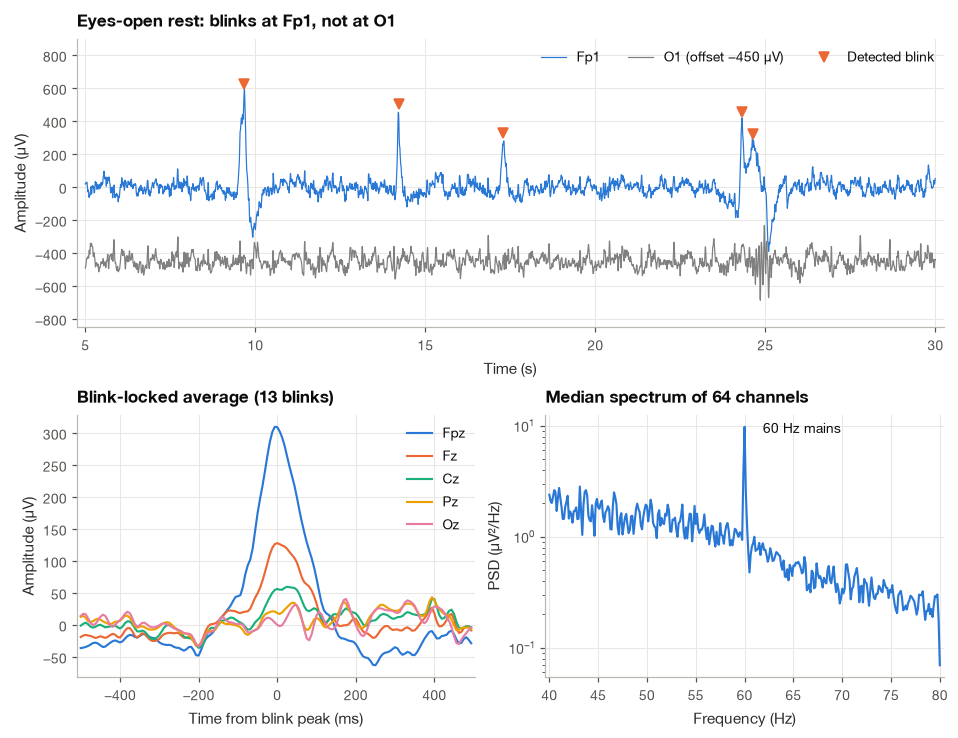

In [17]:
fig = plt.figure(figsize=(8.6, 6.6))
gs = fig.add_gridspec(2, 2, height_ratios=[1.1, 1])
ax = fig.add_subplot(gs[0, :])
seg = (t_open >= 5) & (t_open < 30)
ax.plot(t_open[seg], x_open[idx["Fp1"], seg], color=C[0], lw=0.8, label="Fp1")
ax.plot(t_open[seg], x_open[idx["O1"], seg] - 450, color="0.5", lw=0.8, label="O1 (offset −450 µV)")
in_seg = valid[(valid / fs >= 5) & (valid / fs < 30)]
ax.plot(in_seg / fs, x_open[idx["Fp1"], in_seg] + 60, "v", color=C[1], ms=6, label="Detected blink")
ax.set(xlabel="Time (s)", ylabel="Amplitude (µV)", title="Eyes-open rest: blinks at Fp1, not at O1",
       ylim=(-850, 900))
ax.legend(loc="upper right", ncols=3)

ax = fig.add_subplot(gs[1, 0])
for name, color in zip(("Fpz", "Fz", "Cz", "Pz", "Oz"), (C[0], C[1], C[2], C[3], C[4])):
    ax.plot(1000 * t_blink, blink_avg[midline.index(name)], color=color, label=name)
ax.set(xlabel="Time from blink peak (ms)", ylabel="Amplitude (µV)",
       title=f"Blink-locked average ({len(valid)} blinks)")
ax.legend(loc="upper right")

ax = fig.add_subplot(gs[1, 1])
band = (f_line >= 40) & (f_line <= 80)
ax.semilogy(f_line[band], np.median(psd_open[:, band], axis=0), color=C[0])
ax.annotate("60 Hz mains", (60, np.median(psd_open[:, k60])), textcoords="offset points", xytext=(12, -4),
            fontsize=9)
ax.set(xlabel="Frequency (Hz)", ylabel="PSD (µV²/Hz)", title="Median spectrum of 64 channels")
plt.show()

The averaged blink is about 310 µV at Fpz, about 40% of that at Fz, 20% at Cz and 10% at Oz (single blinks reach almost 600 µV at Fp1). The line-noise check finds a narrow 60 Hz peak about 10 dB above the neighbouring bins in the typical channel, with nothing comparable at 50 Hz. It is real but small: the excess power corresponds to a sinusoid of about 1.4 µV RMS, and it lies far above the EEG bands we care about here. A notch filter (Section 15.4) or simply a 40 Hz low-pass filter handles it. The blinks are a much larger problem. Rejecting the affected segments is the simplest remedy; regression on an EOG channel or independent component analysis (Section 25.2) can remove them while keeping the data.

```{note}
Clinical EEG is traditionally displayed with **negative up**: an upward deflection means the first electrode of the pair is negative relative to the second. Scientific software, including every figure in this book, plots positive up. When you compare a figure with a clinical report or textbook tracing, check the convention before interpreting polarity.
```

(sec-13-1-7)=
## 13.1.7 Clinical Graphoelements

Electroencephalographers describe EEG features as **graphoelements**, named waveforms with defined shapes, durations and contexts. Three of them recur throughout clinical practice.

**Epileptiform spikes and sharp waves.** An interictal epileptiform discharge is a transient that stands out clearly from the background, with a pointed peak and usually a different duration from the surrounding activity. A **spike** lasts from 20 to less than 70 ms and a **sharp wave** from 70 to 200 ms. They are usually surface-negative, are often followed by a slow wave, and have a spatial field: they appear on several neighbouring electrodes, which is how a reader distinguishes them from an electrode artifact. On a bipolar display, the phase reversal of Example 13.1.1 points to the electrode nearest their source. Their presence supports a diagnosis of epilepsy, but they must be interpreted in clinical context, because benign variants with similar shapes exist.

**The 3 Hz spike-and-wave discharge.** The hallmark of typical absence seizures, most often in childhood absence epilepsy, is a burst of generalized, bilaterally synchronous **spike-and-slow-wave complexes** repeating at about 3 per second. The frequency is often slightly faster at the start of the burst and slows towards its end. A burst lasting several seconds typically coincides with a brief lapse of awareness, and such bursts can often be provoked by hyperventilation during the recording.

**K-complexes and sleep spindles.** In stage N2 sleep two graphoelements appear. A **K-complex** is a high-amplitude, well-delineated negative sharp wave immediately followed by a slower positive component, lasting at least 0.5 s and usually maximal over frontal regions; it occurs spontaneously or in response to a sound. A **sleep spindle** is a train of 11–16 Hz waves (most often 12–14 Hz) lasting at least 0.5 s, usually maximal over central regions. K-complexes and spindles define N2 sleep in the standard scoring rules, and we use a spindle as a test signal for the spectrogram in Section 23.2.

The eegmmidb volunteers were healthy and awake, so none of these patterns is present in our data. To make the spike-and-wave description concrete, the next cell builds a **synthetic** discharge. Each complex is a sum of three Gaussian-shaped components: a sharp negative spike (about 50 ms wide), a small positive transient and a large negative slow wave (about 250 ms). The complexes repeat at an instantaneous rate that slows from 3.5 to 2.8 Hz over four seconds, and the background is random noise shaped to have an EEG-like $1/f$ spectrum. All amplitudes and timings are chosen to look plausible, not fitted to any patient.

In [18]:
fs_syn = 250.0
t_syn = np.arange(0, 8, 1 / fs_syn)


def gaussian_bump(t, center, width, amplitude):
    """Gaussian pulse with peak `amplitude` at `center` and standard deviation `width` (s)."""
    return amplitude * np.exp(-0.5 * ((t - center) / width) ** 2)


def spike_wave_complex(t, t0):
    """One synthetic spike-and-slow-wave complex starting at t0 (amplitudes in uV)."""
    return (gaussian_bump(t, t0, 0.010, -180) + gaussian_bump(t, t0 + 0.05, 0.02, 80)
            + gaussian_bump(t, t0 + 0.18, 0.045, -200))


# complex onset times: instantaneous rate slows linearly from 3.5 to 2.8 Hz over 4 s
onsets, t_next = [], 2.0
while t_next < 6.0:
    onsets.append(t_next)
    t_next += 1 / (3.5 - 0.7 * (t_next - 2.0) / 4.0)
discharge = sum(spike_wave_complex(t_syn, t0) for t0 in onsets)

white = rng.normal(size=t_syn.size)
spectrum = np.fft.rfft(white)
freqs = np.fft.rfftfreq(t_syn.size, 1 / fs_syn)
spectrum[1:] /= np.sqrt(freqs[1:])                      # 1/f power spectrum
spectrum[0] = 0
background = np.fft.irfft(spectrum, n=t_syn.size)
background *= 15 / background.std()                     # 15 uV RMS background
synthetic_eeg = background + discharge

print(f"Complexes in the burst: {len(onsets)}")
print(f"Mean repetition rate: {1 / np.mean(np.diff(onsets)):.2f} Hz "
      f"(first interval {1 / (onsets[1] - onsets[0]):.2f} Hz, last {1 / (onsets[-1] - onsets[-2]):.2f} Hz)")

Complexes in the burst: 13
Mean repetition rate: 3.20 Hz (first interval 3.50 Hz, last 2.90 Hz)


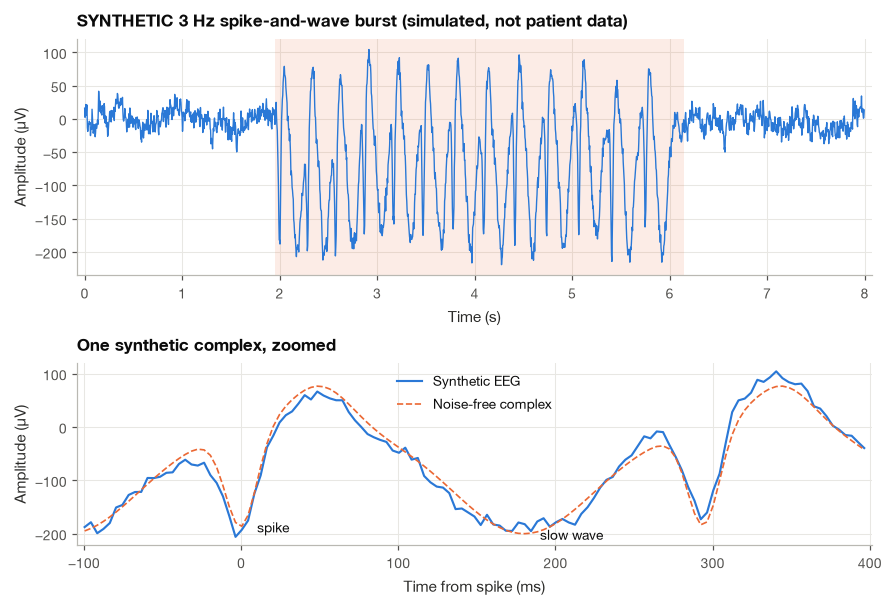

In [19]:
fig, axes = plt.subplots(2, 1, figsize=(8, 5.4), gridspec_kw={"height_ratios": [1.3, 1]})
axes[0].plot(t_syn, synthetic_eeg, color=C[0], lw=0.9)
axes[0].axvspan(onsets[0] - 0.05, onsets[-1] + 0.4, color=C[1], alpha=0.12, lw=0)
axes[0].set(xlabel="Time (s)", ylabel="Amplitude (µV)",
            title="SYNTHETIC 3 Hz spike-and-wave burst (simulated, not patient data)")
zoom = (t_syn >= onsets[2] - 0.1) & (t_syn < onsets[2] + 0.4)
t_zoom = 1000 * (t_syn[zoom] - onsets[2])
axes[1].plot(t_zoom, synthetic_eeg[zoom], color=C[0], label="Synthetic EEG")
axes[1].plot(t_zoom, discharge[zoom], color=C[1], lw=1.1, ls="--", label="Noise-free complex")
for label, lo, hi in [("spike", -20, 20), ("slow wave", 120, 240)]:
    part = (t_zoom >= lo) & (t_zoom <= hi)
    k = np.argmin(discharge[zoom][part])
    axes[1].annotate(label, (t_zoom[part][k], discharge[zoom][part][k]), textcoords="offset points",
                     xytext=(10, -4), fontsize=9)
axes[1].set(xlabel="Time from spike (ms)", ylabel="Amplitude (µV)", title="One synthetic complex, zoomed")
axes[1].legend(loc="upper center")
plt.show()

Because positive is plotted up, the spike and the slow wave point downwards here; a clinical display would show them pointing up. The spectrum of such a burst has a strong peak near 3 Hz with harmonics at 6, 9 and 12 Hz, produced by the sharp spike, which is one reason simple band-power measures confuse epileptiform activity with ordinary rhythms. Automatic spike detection relies on shape, duration and spatial field rather than on spectra alone.

## Summary

The scalp EEG is the summed field of postsynaptic currents in millions of aligned cortical pyramidal neurons. Only synchronized activity is visible: $N$ sources in phase add to $N$ times one source, while random phases add only to $\sqrt{N}$ times, so the EEG measures coordination as much as activity. Volume conduction through the poorly conducting skull smears these fields over centimetres and reduces them to tens of microvolts, which places scalp EEG at the non-invasive, low-resolution end of a family that also includes MEG, ECoG and LFP. Electrode positions follow the proportional 10–20 system and its 10-10 extension, with letters for regions, odd numbers on the left, even on the right and z on the midline. Every channel is a potential difference, and the montage decides what that difference emphasizes: the common average reference and bipolar derivations remove the original reference, and the Hjorth Laplacian approximates the surface Laplacian and isolates local activity, but each can also create or move features, as the inverted blink at O1 showed.

The classic rhythms (delta, theta, alpha, mu, beta, gamma) are conventions that link frequency bands to brain states; in our eyes-closed recording the occipital alpha rhythm dominates. Real recordings also contain artifacts: in the eyes-open run we found 13 blinks of several hundred microvolts at Fp1 and Fp2 and a small 60 Hz line component. Clinical graphoelements such as spikes, 3 Hz spike-and-wave complexes and K-complexes are defined by shape and context, not by spectrum alone. Section 13.2 turns the rhythms into numbers with spectral analysis, and Section 13.3 studies how they change around events.

## Exercises

1. Using equation [(13.1)](#eq-13-1), estimate the RMS amplitude of the sum when $N = 10^6$ sources are present and a fraction $p$ of them are perfectly synchronized, for $p = 0, 0.001, 0.01$ and $0.1$. At what value of $p$ do the synchronized sources contribute as much as the unsynchronized ones?
2. Show that the CAR matrix $\mathbf{P} = \mathbf{I} - \tfrac{1}{M}\mathbf{1}\mathbf{1}^{\top}$ satisfies $\mathbf{P}^2 = \mathbf{P}$ and $\mathbf{P}\mathbf{1} = \mathbf{0}$. What are its eigenvalues, and what does this say about its rank? Verify numerically for $M = 64$.
3. Repeat Example 13.1.1 for a discharge centred *between* electrodes 3 and 4, with potentials $(-5, -15, -45, -45, -15)$ µV. What does the bipolar chain show now, and how would you describe the location of the source?
4. Write a function that computes the Hjorth Laplacian (equation 20.4) for every eegmmidb electrode that has four neighbours in the 10-10 grid, choosing the neighbours automatically as the four nearest electrodes in the 2-D projection. Compare the alpha power topography in the referential and Laplacian montages for run R02.
5. Improve the blink detector of [Section 13.1.6](#sec-13-1-6) by requiring that the deflection be present at both Fp1 and Fp2 with similar amplitude and absent at O1. Apply it to run R02 (eyes closed). How many blinks do you find, and what other slow frontal events trigger the simple detector?
6. Compute the magnitude spectrum of the synthetic spike-and-wave signal of [Section 13.1.7](#sec-13-1-7) with and without the spike component (set its amplitude to zero). Which harmonics depend on the spike, and why does a sharp transient produce them?

## Further Reading

{cite:t}`buzsaki2012` is the standard review of how synaptic currents, cell geometry and synchrony produce the EEG, ECoG and LFP, and {cite:t}`malmivuo1995` derives the dipole fields and volume-conductor models in detail. The original description of the 10–20 system is {cite:t}`jasper1958`; {cite:t}`oostenveld2001` defines the denser 10-10 and 10-5 extensions used by modern caps and by MNE {cite:p}`gramfort2013`. {cite:t}`hjorth1975` introduced the nearest-neighbour Laplacian, and {cite:t}`sornmo2005` covers EEG montages, rhythms and artifacts from a signal processing point of view.